# Part 2 - Supervised Machine Learning

## Import Required Libraries

In [356]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

## Load Cleaned Dataset

In [357]:
df = pd.read_csv("../data/cleaned_data.csv")

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [358]:
print("Dataset Shape :", df.shape)

Dataset Shape : (1460, 81)


In [359]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## Define Features and Target Variables

In [360]:
# Regression Target
y_reg = df["SalePrice"]

# Classification Target
y_clf = (df["SalePrice"] > df["SalePrice"].median()).astype(int)

# Feature Matrix
X = df.drop("SalePrice", axis=1)

In [361]:
print("Feature Matrix Shape :", X.shape)

print("Regression Target Shape :", y_reg.shape)

print("Classification Target Shape :", y_clf.shape)

Feature Matrix Shape : (1460, 80)
Regression Target Shape : (1460,)
Classification Target Shape : (1460,)


In [362]:
print("Regression Target (First 5 Values)")
print(y_reg.head())

print("\nClassification Target Distribution")
print(y_clf.value_counts())

Regression Target (First 5 Values)
0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

Classification Target Distribution
SalePrice
0    732
1    728
Name: count, dtype: int64


## Encode Categorical Features

In [363]:
quality_mapping = {
    "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5
}

X["ExterQual"] = X["ExterQual"].map(quality_mapping)
X["KitchenQual"] = X["KitchenQual"].map(quality_mapping)
X["HeatingQC"] = X["HeatingQC"].map(quality_mapping)

In [364]:
# Fill remaining categorical NaNs before one-hot encoding
# (cleaned_data.csv still has missing values in columns like PoolQC, Alley, Fence)
categorical_cols = X.select_dtypes(include="object").columns
X[categorical_cols] = X[categorical_cols].fillna("None")

print("Remaining NaNs before encoding:", X.isnull().sum().sum())

Remaining NaNs before encoding: 0


In [365]:
X = pd.get_dummies(X, drop_first=True)

In [366]:
print("Encoded Feature Matrix Shape :", X.shape)

Encoded Feature Matrix Shape : (1460, 254)


## Train Test Split

In [367]:
X_train, X_test, y_reg_train, y_reg_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

In [368]:
print("Training Features :", X_train.shape)
print("Testing Features :", X_test.shape)

print("\nRegression Training Labels :", y_reg_train.shape)
print("Regression Testing Labels :", y_reg_test.shape)



Training Features : (1168, 254)
Testing Features : (292, 254)

Regression Training Labels : (1168,)
Regression Testing Labels : (292,)


## Feature Scaling

In [369]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [370]:
print("Scaled Training Shape :", X_train_scaled.shape)
print("Scaled Testing Shape :", X_test_scaled.shape)

Scaled Training Shape : (1168, 254)
Scaled Testing Shape : (292, 254)


## Linear Regression Model

In [371]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_reg_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [372]:
y_pred_reg = linear_model.predict(X_test_scaled)

In [373]:
mse = mean_squared_error(y_reg_test, y_pred_reg)

r2 = r2_score(y_reg_test, y_pred_reg)

print("Mean Squared Error :", mse)
print("R2 Score :", r2)

Mean Squared Error : 7853676624.65433
R2 Score : -0.023903861780403046


## Linear Regression Coefficients

In [374]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_
})

coefficients.head()

,Feature,Coefficient
0,Id,233.433297
1,MSSubClass,883.281185
2,LotFrontage,127.703517
3,LotArea,8141.231368
4,OverallQual,9945.690742


In [375]:
coefficients

,Feature,Coefficient
0,Id,233.433297
1,MSSubClass,883.281185
2,LotFrontage,127.703517
3,LotArea,8141.231368
4,OverallQual,9945.690742
...,...,...
249,SaleCondition_AdjLand,717.160780
250,SaleCondition_Alloca,2086.907320
251,SaleCondition_Family,326.964718
252,SaleCondition_Normal,2388.297771


In [376]:
top_features = coefficients.copy()

top_features["Absolute Coefficient"] = top_features["Coefficient"].abs()

top_features = top_features.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

top_features.head(3)

,Feature,Coefficient,Absolute Coefficient
36,PoolArea,276582.044920,276582.044920
232,PoolQC_None,246036.513173,246036.513173
115,RoofMatl_CompShg,-132333.522779,132333.522779


In [377]:
print("Top 3 Important Features")

print(top_features.head(3))

Top 3 Important Features
              Feature    Coefficient  Absolute Coefficient
36           PoolArea  276582.044920         276582.044920
232       PoolQC_None  246036.513173         246036.513173
115  RoofMatl_CompShg -132333.522779         132333.522779


## Ridge Regression Model

In [378]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_reg_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [379]:
ridge_pred = ridge_model.predict(X_test_scaled)

In [380]:
ridge_mse = mean_squared_error(y_reg_test, ridge_pred)

ridge_r2 = r2_score(y_reg_test, ridge_pred)

print("Ridge Mean Squared Error :", ridge_mse)
print("Ridge R2 Score :", ridge_r2)

Ridge Mean Squared Error : 1385254032.9084635
Ridge R2 Score : 0.8194008969774356


In [381]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "MSE": [mse, ridge_mse],
    "R2 Score": [r2, ridge_r2]
})

comparison

,Model,MSE,R2 Score
0,Linear Regression,7.853677e+09,-0.023904
1,Ridge Regression,1.385254e+09,0.819401


In [382]:
from imblearn.over_sampling import SMOTE

print("SMOTE imported successfully")

SMOTE imported successfully


## Logistic Regression Classification

In [383]:
# Reuse the SAME encoded X used for regression — just a different target
y = y_clf   # already defined earlier as (SalePrice > median).astype(int)

print("Reusing encoded feature matrix:", X.shape)
print(y.value_counts())

Reusing encoded feature matrix: (1460, 254)
SalePrice
0    732
1    728
Name: count, dtype: int64


In [384]:
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [385]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_clf_train_scaled = scaler.fit_transform(X_clf_train)

X_clf_test_scaled = scaler.transform(X_clf_test)

In [386]:
print(y_clf_train.value_counts())

SalePrice
0    586
1    582
Name: count, dtype: int64


In [387]:
minority_pct = y_clf_train.value_counts(normalize=True).min() * 100
print(f"Minority class %: {minority_pct:.2f}%")

if minority_pct < 35:
    print("Imbalance detected -> applying SMOTE")
    smote = SMOTE(random_state=42)
    X_train_final, y_train_final = smote.fit_resample(X_clf_train_scaled, y_clf_train)
else:
    print("Classes already balanced -> SMOTE not required, using data as-is")
    X_train_final, y_train_final = X_clf_train_scaled, y_clf_train

Minority class %: 49.83%
Classes already balanced -> SMOTE not required, using data as-is


In [388]:
logistic_model = LogisticRegression(random_state=42)
logistic_model.fit(X_train_final, y_train_final)   

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## Logistic Regression Model

In [389]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

In [390]:
logistic_model = LogisticRegression(random_state=42)

logistic_model.fit(X_train_final, y_train_final)  

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [391]:
y_pred = logistic_model.predict(X_clf_test_scaled)

y_prob = logistic_model.predict_proba(X_clf_test_scaled)[:, 1]

In [392]:
accuracy = accuracy_score(y_clf_test, y_pred)

print("Accuracy :", accuracy)

Accuracy : 0.8801369863013698


In [393]:
precision = precision_score(y_clf_test, y_pred)

print("Precision :", precision)

Precision : 0.8775510204081632


In [394]:
recall = recall_score(y_clf_test, y_pred)

print("Recall :", recall)

Recall : 0.8835616438356164


In [395]:
f1 = f1_score(y_clf_test, y_pred)

print("F1 Score :", f1)

F1 Score : 0.8805460750853242


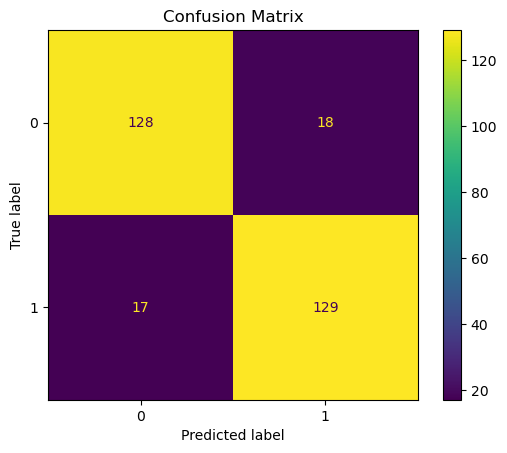

In [396]:
cm = confusion_matrix(y_clf_test, y_pred)

display = ConfusionMatrixDisplay(confusion_matrix=cm)

display.plot()

plt.title("Confusion Matrix")

plt.show()

## ROC Curve and AUC Score

In [397]:
fpr, tpr, thresholds = roc_curve(y_clf_test, y_prob)

auc_score = roc_auc_score(y_clf_test, y_prob)

print("AUC Score :", auc_score)

AUC Score : 0.9598423719271909


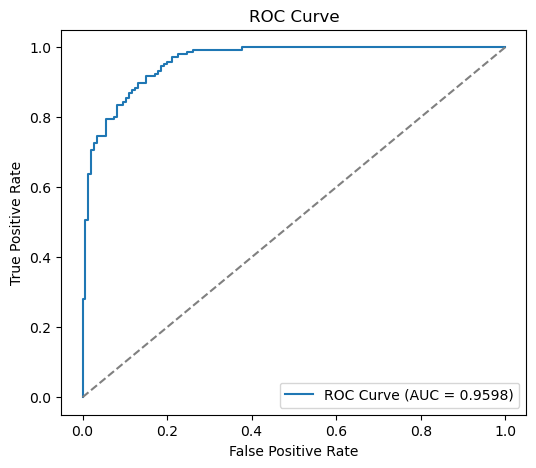

In [398]:
plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.4f})")
plt.plot([0,1],[0,1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

# Decision Threshold Sensitivity

In this section, the Logistic Regression model is evaluated using different decision thresholds ranging from 0.30 to 0.70. Precision, Recall, and F1 Score are calculated at each threshold to observe how the model performance changes.

In [399]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

In [400]:
probabilities = logistic_model.predict_proba(X_clf_test_scaled)[:, 1]

In [401]:
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for t in thresholds:

    prediction = (probabilities >= t).astype(int)

    precision = precision_score(y_clf_test, prediction)

    recall = recall_score(y_clf_test, prediction)

    f1 = f1_score(y_clf_test, prediction)

    results.append([t, precision, recall, f1])

In [402]:
threshold_table = pd.DataFrame(
    results,
    columns=[
        "Threshold",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

threshold_table

,Threshold,Precision,Recall,F1 Score
0,0.3,0.857143,0.904110,0.880000
1,0.4,0.856209,0.897260,0.876254
2,0.5,0.877551,0.883562,0.880546
3,0.6,0.881944,0.869863,0.875862
4,0.7,0.887324,0.863014,0.875000


# Logistic Regression with Strong Regularization

In this section, a second Logistic Regression model is trained using a smaller value of C (C = 0.01). The performance of this model is compared with the baseline Logistic Regression model.

In [403]:
logistic_model_c001 = LogisticRegression(
    C=0.01,
    max_iter=1000,
    random_state=42
)

logistic_model_c001.fit(
    X_train_final,
    y_train_final
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,0.01
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [404]:
y_pred_c001 = logistic_model_c001.predict(
    X_clf_test_scaled
)

y_prob_c001 = logistic_model_c001.predict_proba(
    X_clf_test_scaled
)[:, 1]

In [405]:
precision_c001 = precision_score(
    y_clf_test,
    y_pred_c001
)

recall_c001 = recall_score(
    y_clf_test,
    y_pred_c001
)

f1_c001 = f1_score(
    y_clf_test,
    y_pred_c001
)

auc_c001 = roc_auc_score(
    y_clf_test,
    y_prob_c001
)

print("Precision :", precision_c001)
print("Recall :", recall_c001)
print("F1 Score :", f1_c001)
print("AUC Score :", auc_c001)

Precision : 0.9166666666666666
Recall : 0.9041095890410958
F1 Score : 0.9103448275862069
AUC Score : 0.9741977857008819


In [406]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (C=1.0)",
        "Logistic Regression (C=0.01)"
    ],
    "Precision": [
        precision,
        precision_c001
    ],
    "Recall": [
        recall,
        recall_c001
    ],
    "F1 Score": [
        f1,
        f1_c001
    ],
    "AUC": [
        auc_score,
        auc_c001
    ]
})

comparison

,Model,Precision,Recall,F1 Score,AUC
0,Logistic Regression (C=1.0),0.887324,0.863014,0.875000,0.959842
1,Logistic Regression (C=0.01),0.916667,0.904110,0.910345,0.974198


# Bootstrap Confidence Interval for AUC Difference

In this section, bootstrap sampling is used to compare the AUC scores of the two Logistic Regression models. The AUC difference is calculated over 500 bootstrap samples to estimate the confidence interval.

In [407]:
import numpy as np

In [408]:
auc_differences = []

n_iterations = 500

np.random.seed(42)

In [409]:
for i in range(n_iterations):

    sample_index = np.random.choice(
        len(y_clf_test),
        size=len(y_clf_test),
        replace=True
    )

    y_sample = y_clf_test.iloc[sample_index]

    prob_c1 = y_prob[sample_index]

    prob_c001 = y_prob_c001[sample_index]

    auc_c1 = roc_auc_score(y_sample, prob_c1)

    auc_c001_boot = roc_auc_score(y_sample, prob_c001)

    auc_differences.append(
        auc_c1 - auc_c001_boot
    )

In [410]:
mean_difference = np.mean(auc_differences)

lower_limit = np.percentile(
    auc_differences,
    2.5
)

upper_limit = np.percentile(
    auc_differences,
    97.5
)

In [411]:
print("Mean AUC Difference :", mean_difference)

print("95% Confidence Interval")

print("Lower Limit :", lower_limit)

print("Upper Limit :", upper_limit)

Mean AUC Difference : -0.014432245318563172
95% Confidence Interval
Lower Limit : -0.02666925200942315
Upper Limit : -0.005163428514643209


In [412]:
if lower_limit > 0 or upper_limit < 0:
    print("The confidence interval does not include zero.")
else:
    print("The confidence interval includes zero.")

The confidence interval does not include zero.
